# Final ML models: selection, evaluation and inference

This notebook presents the initial classifier baseline, the selected original English ensemble, and the later structured-state candidate. Historical evaluation and current inference examples are labelled separately.

**Run:** Python 3.12 → `pip install -r requirements.txt` → restart kernel → **Run All**. Keep `src/`, `artifacts/` and `models/` beside this notebook. Default execution is offline, without fitting or threshold search.

**Contents:** [Setup](#setup) · [Models](#1-model-overview) · [Baseline](#2-initial-classifier-baseline) · [Selection](#3-original-ensemble-selection) · [Test report](#4-original-ensemble-evaluation) · [Context/calibration](#5-context-and-calibration-trials) · [Latest validation](#6-latest-recorded-extractor-validation) · [Inference](#7-current-inference-examples) · [Limits](#8-reproducibility-and-limits)

Scores reflect weak binary annotations and are not clinical probabilities. The structured-state candidate remains experimental and was not promoted.

## Setup

Verify packaged source/model files and prepare an ignored workspace for writable outputs.

In [1]:
from pathlib import Path
import sys, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PACKAGE = Path.cwd().resolve()
if not (PACKAGE / 'src/notebook_support.py').is_file():
    PACKAGE = PACKAGE / 'notebook-release'
sys.path.insert(0, str(PACKAGE / 'src'))
from notebook_support import initialize, read_json, facts_frame, prediction_row

ARTIFACTS = initialize(PACKAGE)
WORK = PACKAGE / '.notebook_runtime'
RESEARCH = ARTIFACTS / 'multilingual'
from triage_pipeline import extract_info, to_features, process_turn, load_state_model, predict_from_state
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.precision', 4)
print('Ready: source and model hashes verified.')

Ready: source and model hashes verified.


## 1. Model overview

| File | Role | Threshold | Status |
|---|---|---:|---|
| `models/best_model.joblib` | Original equal-vote CatBoost + histogram gradient boosting + ExtraTrees ensemble | 0.48 | Preserved English benchmark |
| `models/candidate_model.joblib` | Structured-state v3 ensemble with sigmoid mapping | 0.15 | Experimental candidate |

The original deployed v2 file remains in the original project. This release contains the original benchmark and the latest candidate, with unchanged model bytes.

## 2. Initial classifier baseline

**Approach:** Question-only TF-IDF with class-weighted logistic regression, compared with a majority baseline. Exact normalized-question duplicates were grouped before splitting.

**Historical result on its own split:** macro F1 **0.8101**, accuracy **93.09%**, critical recall **34/52 (65.4%)**, with **18 missed critical cases**.

**Takeaway:** This established an initial reference. Its split differs from the later ensemble split, so the numbers are not a controlled comparison.

[Original baseline code and notes](research/02_urgency_classifier_baseline.py)

## 3. Original ensemble selection

**Approach:** Clinical facts → dictionary vectorization → candidate classifiers → validation selection. Eight model families were considered. The table below reads the saved run, without rerunning optimization.

[Training/tuning implementation](src/triage_tuning.py) · [Complete saved metrics and parameters](artifacts/tuned/metrics.json)

In [2]:
original = read_json(ARTIFACTS / 'tuned/metrics.json')
keys = ['selected_model', 'threshold', 'seed', 'search_trials', 'completed_trials', 'failed_trials']
display(pd.DataFrame([(key, original[key]) for key in keys],
                     columns=['Setting', 'Saved value']).set_index('Setting'))
display(pd.Series(original['split_counts'], name='Cases').to_frame())
display(pd.DataFrame({'Model family': original['model_families']}))

,Saved value
Setting,
selected_model,vote_catboost_hist_gradient_boosting_extra_trees_1_1_1
threshold,0.48
seed,20261009
search_trials,157
completed_trials,108
failed_trials,1


,Cases
train,23758
validation,5091
test,5092


,Model family
0,logistic_regression
1,sgd
2,random_forest
3,extra_trees
4,hist_gradient_boosting
5,xgboost
6,lightgbm
7,catboost


**Selected parameters:** Best settings saved by model family. Full per-trial Optuna logs are not available here; missing trials have not been reconstructed.

In [3]:
rows = []
for family, parameters in original['best_parameters'].items():
    for parameter, value in parameters.items():
        rows.append({'Family': family, 'Parameter': parameter, 'Value': str(value)})
display(pd.DataFrame(rows).set_index(['Family', 'Parameter']))

Value
Family                 Parameter                                
logistic_regression    weight                               none
                       C                      1.3039774937773738
                       penalty                                l1
sgd                    weight                               none
                       alpha               5.653134713470281e-05
                       l1_ratio               0.7048374739989535
random_forest          weight                               none
                       n_estimators                          350
                       max_depth                              40
                       min_samples_leaf                        1
                       min_samples_split                      11
                       max_features                          1.0
extra_trees            weight                               none
                       n_estimators                          450
                       max_depth                              40
                       min_samples_leaf                        1
                       min_samples_split                      12
                       max_features                         0.25
hist_gradient_boosting weight                               none
                       max_iter                              550
                       learning_rate        0.025213297513562046
                       max_leaf_nodes                         63
                       min_samples_leaf                       10
                       l2_regularization      1.4324588515722552
xgboost                weight                               sqrt
                       n_estimators                          300
                       learning_rate         0.08339542248957853
                       subsample              0.9735380090951029
                       colsample_bytree       0.7519716948413848
                       reg_alpha          0.00011842087601414682
                       reg_lambda            0.10455103686275444
                       max_depth                               6
                       min_child_weight       2.5318888231286683
lightgbm               weight                           balanced
                       n_estimators                          200
                       learning_rate         0.08107654385902731
                       subsample              0.8047121544930498
                       colsample_bytree        0.998077024385053
                       reg_alpha           0.0001150627413848855
                       reg_lambda              25.14806422923282
                       num_leaves                             61
                       max_depth                              -1
                       min_child_samples                      10
catboost               weight                               none
                       iterations                            500
                       depth                                   7
                       learning_rate            0.19810720542584
                       l2_leaf_reg             8.296846595589463
                       random_strength        0.6576833758619088

## 4. Original ensemble evaluation

**Historical result:** The saved ensemble test report uses historical weak annotations. This dataset had appeared in earlier experiments; it is not an external clinical cohort. No test cases are loaded or rescored here.

In [4]:
report = original['test']['classification_report']
rows = {key: value for key, value in report.items() if isinstance(value, dict)}
display(pd.DataFrame.from_dict(rows, orient='index'))
print(f"Historical accuracy: {report['accuracy']:.4f}")

,precision,recall,f1-score,support
non_emergency,0.9906,0.9650,0.9776,4055.0
emergency,0.8757,0.9643,0.9179,1037.0
macro avg,0.9331,0.9647,0.9477,5092.0
weighted avg,0.9672,0.9648,0.9655,5092.0


Historical accuracy: 0.9648


## 5. Context and calibration trials

**Question:** Can richer contextual facts improve the representation while retaining the ensemble architecture?

**Historical protocol:** A separate calibration-fit subset and 2,546-case selection-validation subset. This validation set informed development.

[Feature projection](src/ml_features.py) · [Comparison report](artifacts/integration_v3/metrics.json) · [Calibration diagnostics](artifacts/integration_v3/calibration_validation.csv)

In [5]:
OUTPUT = ARTIFACTS / 'integration_v3'
metrics = read_json(OUTPUT / 'metrics.json')
comparison = pd.DataFrame(metrics['validation_comparison'])
columns = ['version', 'threshold', 'macro_f1', 'emergency_precision', 'emergency_recall',
           'false_positives', 'false_negatives', 'roc_auc']
display(comparison[columns].set_index('version'))
display(pd.read_csv(OUTPUT / 'calibration_validation.csv'))

,threshold,macro_f1,emergency_precision,emergency_recall,false_positives,false_negatives,roc_auc
version,,,,,,,
old_features_old_classifier/original_deployed,0.480,0.9494,0.8857,0.9575,64,22,0.9924
old_features_old_classifier/sigmoid,0.540,0.9509,0.8947,0.9517,58,25,0.9924
new_features_same_architecture/sigmoid,0.130,0.8907,0.7384,0.9537,175,24,0.9725
new_features_without_detailed_facts/sigmoid,0.125,0.8843,0.7250,0.9517,187,25,0.9696
repaired/none,0.175,0.9120,0.7901,0.9517,131,25,0.9801
repaired/sigmoid,0.150,0.9120,0.7901,0.9517,131,25,0.9801


,mapping,threshold,macro_f1,emergency_precision,emergency_recall,false_positives,false_negatives,true_positives,true_negatives,roc_auc,brier,log_loss,ece_10_bins
0,sigmoid,0.150,0.912,0.7901,0.9517,131,25,493,1897,0.9801,0.0364,0.1353,0.0103
1,none,0.175,0.912,0.7901,0.9517,131,25,493,1897,0.9801,0.0368,0.1361,0.0147


**Takeaway:** Context changes regressed from original benchmark macro F1 0.9494 to 0.8907. The repaired projection recovered to 0.9120, with 131 false positives and 25 false negatives. The regression remains unresolved. The saved sigmoid threshold 0.15 is experimental.

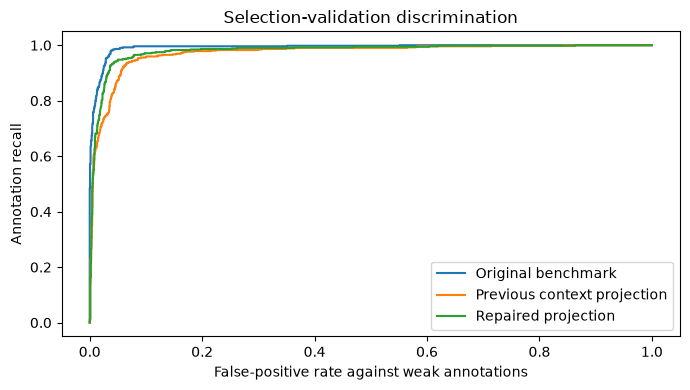

Historical selection-validation curves; bundled model hashes were checked during setup.


In [6]:
from sklearn.metrics import roc_curve
old=pd.read_csv(ARTIFACTS/'ml_regression/ensemble_validation_scores.csv')
new=pd.read_csv(OUTPUT/'validation_predictions.csv')
fig,ax=plt.subplots(figsize=(7,4))
for label,frame,column in [('Original benchmark',old[(old.representation=='old_features_old_classifier')&(old.mapping=='none')],'raw_score'),('Previous context projection',old[(old.representation=='new_features_same_architecture')&(old.mapping=='none')],'raw_score'),('Repaired projection',new,'raw_score_emergency')]:
    x,y,_=roc_curve(frame.emergency_label,frame[column]);ax.plot(x,y,label=label)
ax.set(xlabel='False-positive rate against weak annotations',ylabel='Annotation recall',title='Selection-validation discrimination');ax.legend();fig.tight_layout();plt.show()

print('Historical selection-validation curves; bundled model hashes were checked during setup.')

## 6. Latest recorded extractor validation

**Historical reevaluation:** The saved v3 ensemble and 0.15 threshold stayed fixed while the extractor changed. This table reads the latest saved validation artifact; it does not freshly assess every current source change.

In [7]:
validation = read_json(RESEARCH / 'english_validation.json')
display(pd.DataFrame([
    {'Version': 'Prior v3', **validation['before']},
    {'Version': 'Updated extractor, same v3', **validation['after']},
]).set_index('Version'))
assert not validation['classifier_retrained'] and not validation['threshold_tuned']
print('Recorded cases:', validation['records'])
print('Recorded changed predictions:', validation['changed_predictions'])

,threshold,macro_f1,emergency_precision,emergency_recall,false_positives,false_negatives,true_positives,true_negatives,roc_auc
Version,,,,,,,,,
Prior v3,0.15,0.9120,0.7901,0.9517,131,25,493,1897,0.9801
"Updated extractor, same v3",0.15,0.9113,0.7897,0.9498,131,26,492,1897,0.9799


Recorded cases: 2546
Recorded changed predictions: 3


## 7. Current inference examples

**Original English model:** Use its frozen preprocessing snapshot to retain its training representation. Do not pass current-extractor features directly into this historical model.

In [8]:
from pipeline_validation import predict_original_benchmark
questions = [
    'I have severe chest pain and difficulty breathing now.',
    'I need a routine prescription refill.',
]
rows = [{'Question': text, **prediction_row(predict_original_benchmark(text))} for text in questions]
display(pd.DataFrame(rows))

C:\Users\moura\Desktop\hackcure\hackcure-nlp-urgency\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Question,emergency_label,model_score_emergency,model_score_non_emergency
0,I have severe chest pain and difficulty breathing now.,1,0.9995,0.0005
1,I need a routine prescription refill.,0,0.0041,0.9959


**Structured-state candidate:** Load the explicit v3 adapter and obtain independent model scores. The adapter verifies the preserved model/feature contract; it does not establish extraction accuracy.

In [9]:
from triage_pipeline import new_patient_state, update_patient_state
candidate = load_state_model('experimental_v3')
state = update_patient_state(new_patient_state(), questions[0])
display(facts_frame(state['facts']))
prediction = predict_from_state(state, bundle=candidate)
display(pd.DataFrame([prediction_row(prediction)]))
assert prediction['model_candidate_only']
assert not prediction['score_is_clinically_calibrated']
assert np.isclose(prediction['model_score_emergency'] + prediction['model_score_non_emergency'], 1)
print('Compatibility checks passed; candidate remains experimental.')

,text,kind,name,status,temporality,experiencer,severity
0,chest,anatomy,chest,confirmed,current,patient,"{'text': 'severe', 'value': 'severe', 'start': 7, 'end': 13, ..."
1,chest pain,symptom,chest,confirmed,current,patient,"{'text': 'severe', 'value': 'severe', 'start': 7, 'end': 13, ..."
2,difficulty breathing,symptom,breath,confirmed,current,patient,"{'text': 'severe', 'value': 'severe', 'start': 7, 'end': 13, ..."


,emergency_label,model_score_emergency,model_score_non_emergency,classification_threshold,model_version,model_candidate_only
0,1,0.9948,0.0052,0.15,experimental_v3,True


Compatibility checks passed; candidate remains experimental.


## 8. Reproducibility and limits

- Saved model bytes and source snapshots are verified before inference. No model was promoted.
- The original ensemble has a historical weak-label test report; the candidate has recorded selection-validation comparisons.
- Calibration/threshold selection used English weak annotations. Scores are not clinical probabilities, and Tunisian clinical generalization is unestablished.
- Full fitting requires the original training dataset, caches and split artifacts. Large inputs and local environments are excluded here.
- The context-feature regression and independent clinical evaluation remain outstanding.

[Source manifest](source_manifest.json) · [Model manifest](model_manifest.json) · [NLP experiments](01_nlp_extractor_trials.ipynb) · [Package instructions](README.md)